# 📊 01. Exploratory Data Analysis & Imbalance Characterization
### Project: XAI System in Banking: AI Anomaly-Driven Credit Card Fraud Detection and Interpretation
**Objective:** In-depth exploratory data analysis of the European cardholder credit card fraud dataset (`mlg-ulb/creditcardfraud`), characterizing extreme class imbalance ($0.172\%$), feature distributions, time-domain dynamics, and financial transaction amounts.

In [1]:
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT_DIR))

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
print(f"Working directory: {ROOT_DIR}")

Working directory: /home/swayam-shah/repos/XAI-System-in-Banking-AI-Anomaly-Driven-Credit-Card-Fraud-Detection-and-Interpretation


## 1. Data Ingestion & Shape Verification
The primary dataset consists of credit card transactions made by European cardholders in September 2013 over a two-day period.

In [2]:
data_path = ROOT_DIR / "data/raw/creditcard.csv"
if not data_path.exists():
    from scripts.download_data import download_dataset
    download_dataset("mlg-ulb/creditcardfraud", str(ROOT_DIR / "data/raw"))

df = pd.read_csv(data_path)
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Dataset shape: 284,807 rows × 31 columns


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Extreme Class Imbalance Characterization
In credit card fraud detection, fraudulent transactions represent a minute fraction of overall transaction volume. We evaluate the exact class distribution below.

Legitimate Transactions (Class 0): 284,315 (99.8273%)
Fraudulent Transactions (Class 1): 492 (0.1727%)
Imbalance Ratio: ~577:1


/tmp/ipykernel_5431/691134092.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=["Legitimate (0)", "Fraud (1)"], y=[normal_count, fraud_count], palette=["#2b5c8f", "#d9534f"], ax=ax)


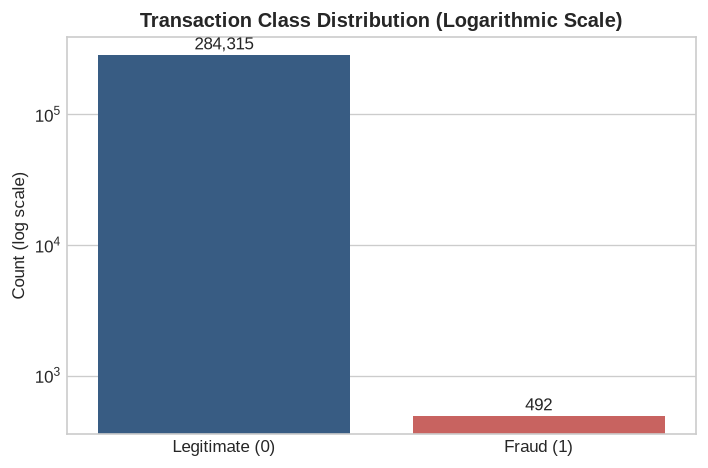

In [3]:
class_counts = df["Class"].value_counts()
normal_count = class_counts[0]
fraud_count = class_counts[1]
fraud_pct = (fraud_count / len(df)) * 100

print(f"Legitimate Transactions (Class 0): {normal_count:,} ({100 - fraud_pct:.4f}%)")
print(f"Fraudulent Transactions (Class 1): {fraud_count:,} ({fraud_pct:.4f}%)")
print(f"Imbalance Ratio: ~{normal_count // fraud_count}:1")

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=["Legitimate (0)", "Fraud (1)"], y=[normal_count, fraud_count], palette=["#2b5c8f", "#d9534f"], ax=ax)
ax.set_yscale("log")
ax.set_title("Transaction Class Distribution (Logarithmic Scale)", fontsize=12, fontweight="bold")
ax.set_ylabel("Count (log scale)")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha="center", va="center", xytext=(0, 6), textcoords="offset points", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Transaction Amount Analysis & Logarithmic Transformation
Transaction amounts exhibit extreme right-skewness: while legitimate transactions span small everyday amounts up to corporate expenses, fraud patterns often concentrate in distinct amounts to avoid trigger thresholds.

Transaction Amount Summary:
Legitimate: count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Fraudulent: count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64


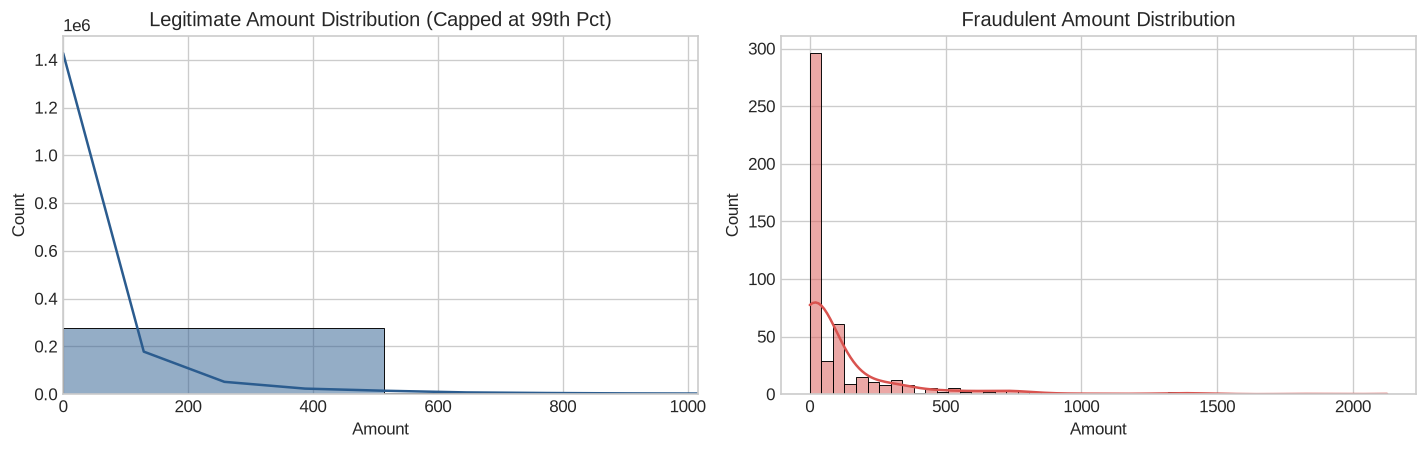

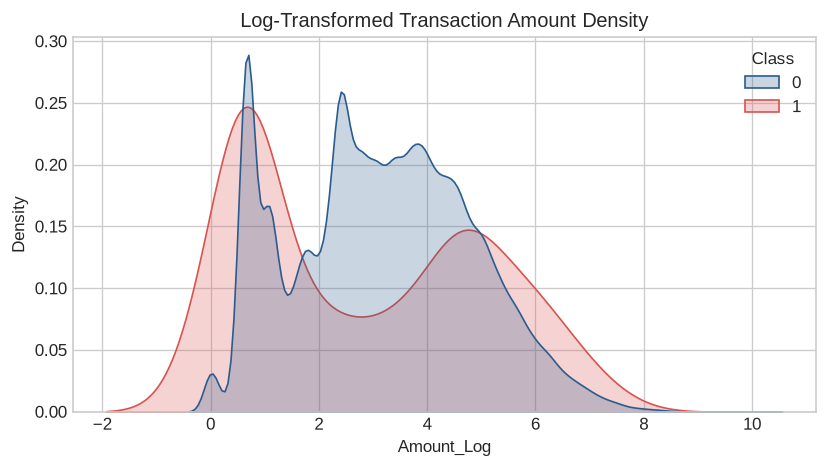

In [4]:
print("Transaction Amount Summary:")
print("Legitimate:", df[df["Class"] == 0]["Amount"].describe())
print("\nFraudulent:", df[df["Class"] == 1]["Amount"].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[df["Class"] == 0]["Amount"], bins=50, ax=axes[0], color="#2b5c8f", kde=True)
axes[0].set_title("Legitimate Amount Distribution (Capped at 99th Pct)")
axes[0].set_xlim(0, df[df["Class"] == 0]["Amount"].quantile(0.99))

sns.histplot(df[df["Class"] == 1]["Amount"], bins=50, ax=axes[1], color="#d9534f", kde=True)
axes[1].set_title("Fraudulent Amount Distribution")
plt.tight_layout()
plt.show()

# Log amount transform
df["Amount_Log"] = np.log1p(df["Amount"])
fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=df, x="Amount_Log", hue="Class", common_norm=False, palette=["#2b5c8f", "#d9534f"], fill=True, ax=ax)
ax.set_title("Log-Transformed Transaction Amount Density")
plt.tight_layout()
plt.show()

## 4. Time-Domain Periodicity & Hourly Cyclic Encoding
Transactions span 48 consecutive hours. Legitimate activity follows diurnal cycles, whereas automated bot attacks frequently strike during off-peak night hours.

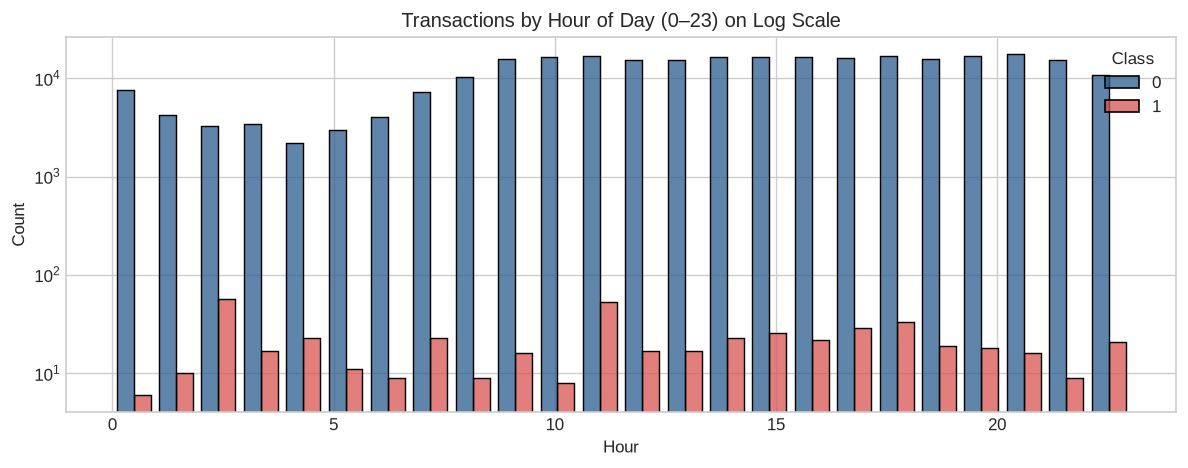

In [5]:
df["Hour"] = (df["Time"] // 3600) % 24
fig, ax = plt.subplots(figsize=(10, 4))
sns.histplot(data=df, x="Hour", hue="Class", multiple="dodge", shrink=0.8, bins=24, palette=["#2b5c8f", "#d9534f"], ax=ax)
ax.set_yscale("log")
ax.set_title("Transactions by Hour of Day (0–23) on Log Scale")
plt.tight_layout()
plt.show()

## 5. PCA Feature Correlation Spectrum with Fraud Label
We evaluate which anonymized features exhibit strongest correlation with `Class`.

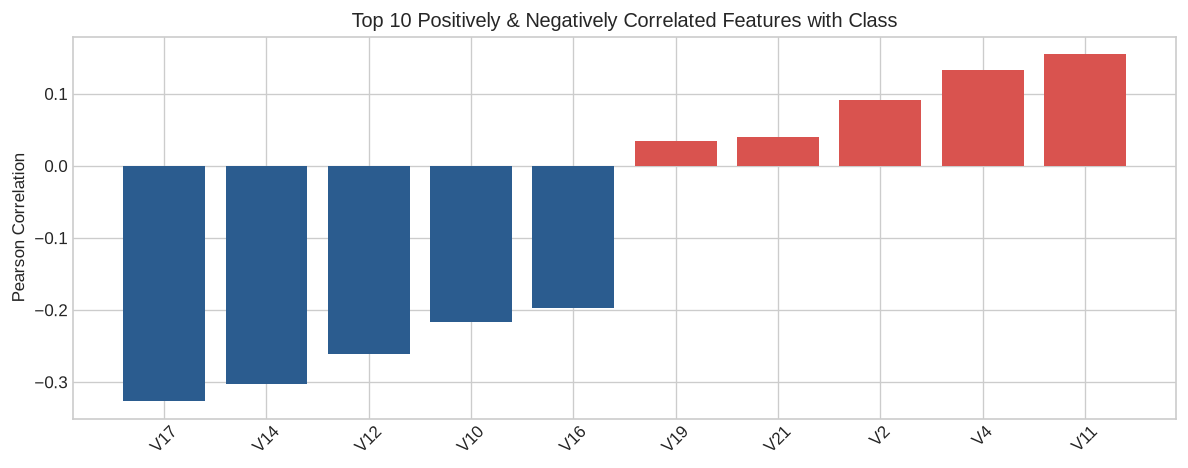

In [6]:
correlations = df.corr()["Class"].drop(["Class", "Amount_Log"]).sort_values()
top_neg = correlations.head(5)
top_pos = correlations.tail(5)
top_corr = pd.concat([top_neg, top_pos])

fig, ax = plt.subplots(figsize=(10, 4))
colors = ["#2b5c8f" if c < 0 else "#d9534f" for c in top_corr.values]
ax.bar(top_corr.index, top_corr.values, color=colors)
ax.set_title("Top 10 Positively & Negatively Correlated Features with Class")
ax.set_ylabel("Pearson Correlation")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()